In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shwetahadole/diabetes/diabetes.csv


In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv("/kaggle/input/datasets/shwetahadole/diabetes/diabetes.csv")

# Display first 5 rows
print("First 5 rows:")
print(df.head())

# Display shape
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Display statistical summary
print("\nStatistical Summary:")
print(df.describe())

# Display target distribution
print("\nOutcome Distribution:")
print(df["Outcome"].value_counts())

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape:
(768, 9)

Column Names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 t

In [3]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("/kaggle/input/datasets/shwetahadole/diabetes/diabetes.csv")

# Columns where 0 represents an invalid/missing measurement
columns_with_zero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Check zero values
print("Zero values before cleaning:")

for column in columns_with_zero:
    print(column, ":", (df[column] == 0).sum())

# Replace zero with NaN
for column in columns_with_zero:
    df[column] = df[column].replace(0, np.nan)

# Check missing values
print("\nMissing values after converting zeros:")

print(df.isnull().sum())

# Fill missing values using median
for column in columns_with_zero:
    df[column] = df[column].fillna(df[column].median())

# Check missing values after cleaning
print("\nMissing values after cleaning:")

print(df.isnull().sum())

# Display cleaned dataset
print("\nCleaned Dataset:")
print(df.head())

Zero values before cleaning:
Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11

Missing values after converting zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing values after cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Cleaned Dataset:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0    125.0  33.6   
1            1     85.0           66.0           29.0    125.0  26.6   
2      

Dataset Shape:
(768, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB

Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


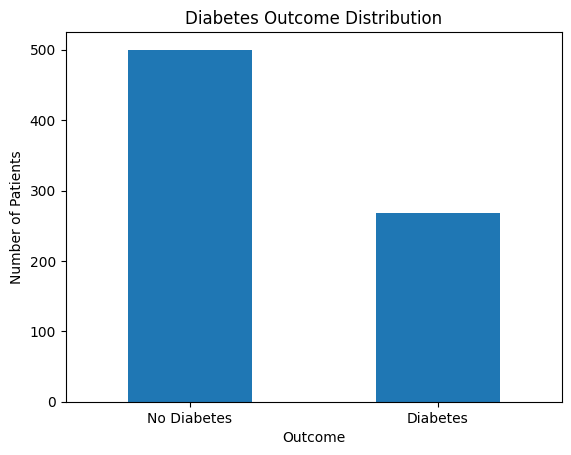


Average Values by Outcome:
         Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
Outcome                                                                      
0           3.298000  110.682000      70.920000      27.726000  127.792000   
1           4.865672  142.130597      75.123134      31.686567  164.701493   

               BMI  DiabetesPedigreeFunction        Age  
Outcome                                                  
0        30.885600                  0.429734  31.190000  
1        35.383582                  0.550500  37.067164  


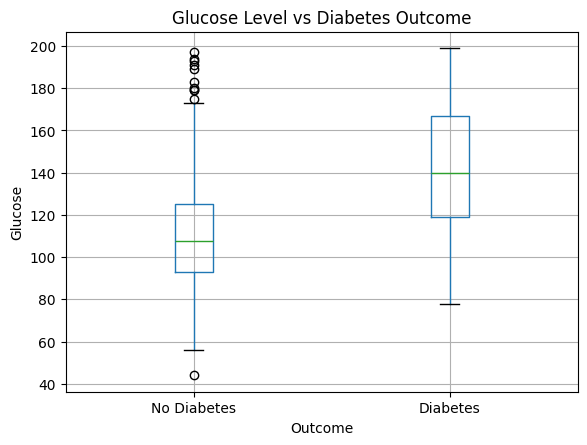

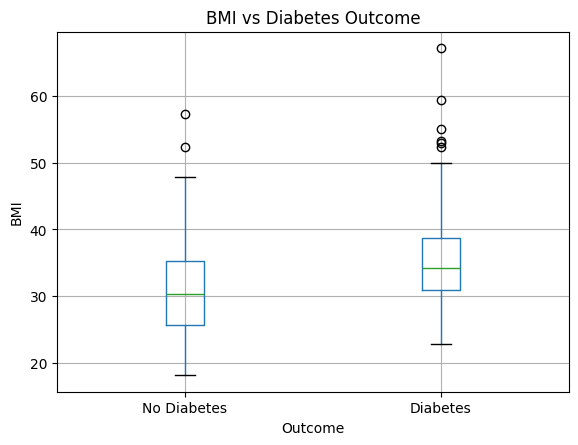

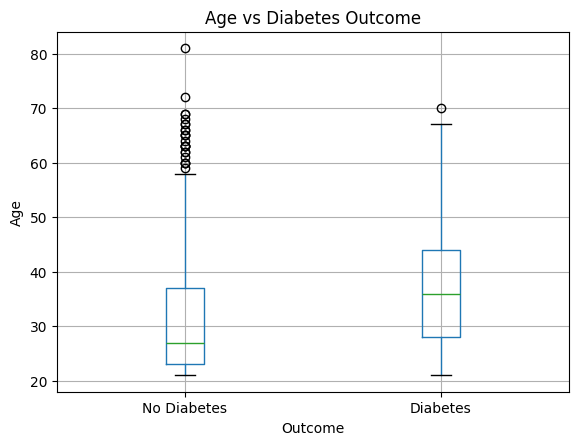


Correlation with Outcome:
Outcome                     1.000000
Glucose                     0.492782
BMI                         0.312038
Age                         0.238356
Pregnancies                 0.221898
SkinThickness               0.214873
Insulin                     0.203790
DiabetesPedigreeFunction    0.173844
BloodPressure               0.165723
Name: Outcome, dtype: float64


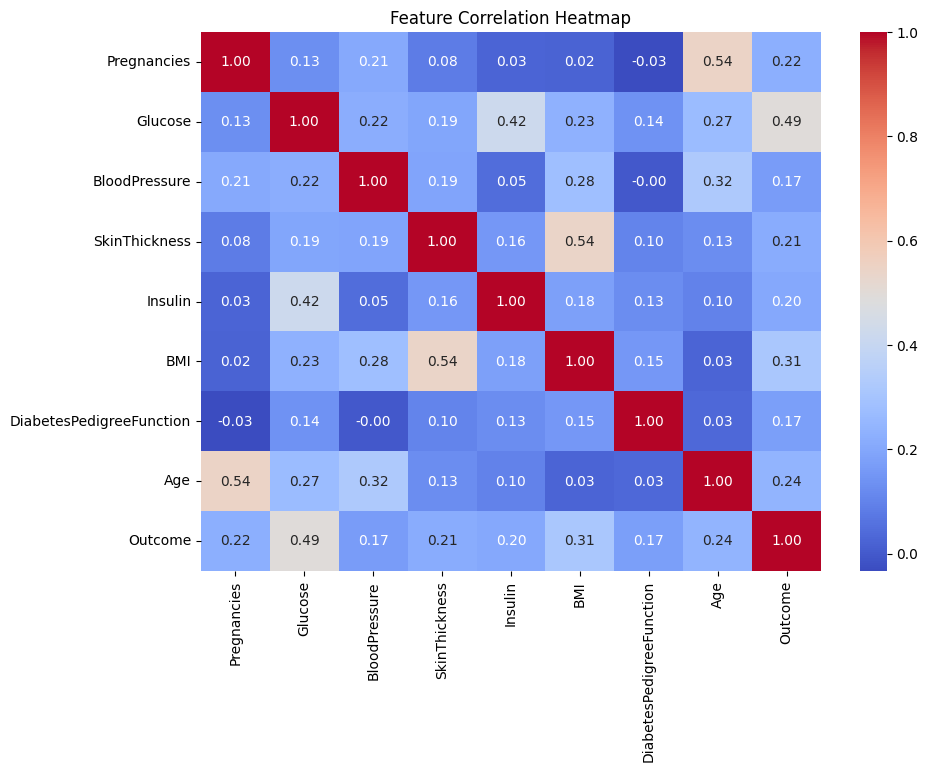

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("/kaggle/input/datasets/shwetahadole/diabetes/diabetes.csv")

# Columns where 0 represents missing/invalid values
columns_with_zero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace zero with NaN
for column in columns_with_zero:
    df[column] = df[column].replace(0, np.nan)

# Fill missing values with median
for column in columns_with_zero:
    df[column] = df[column].fillna(df[column].median())

# ----------------------------------
# 1. Dataset information
# ----------------------------------

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

# ----------------------------------
# 2. Outcome distribution
# ----------------------------------

print("\nOutcome Distribution:")
print(df["Outcome"].value_counts())

df["Outcome"].value_counts().plot(kind="bar")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"], rotation=0)

plt.show()

# ----------------------------------
# 3. Group averages
# ----------------------------------

print("\nAverage Values by Outcome:")
print(df.groupby("Outcome").mean())

# ----------------------------------
# 4. Glucose vs Outcome
# ----------------------------------

df.boxplot(column="Glucose", by="Outcome")

plt.title("Glucose Level vs Diabetes Outcome")
plt.suptitle("")
plt.xlabel("Outcome")
plt.ylabel("Glucose")

plt.xticks([1, 2], ["No Diabetes", "Diabetes"])

plt.show()

# ----------------------------------
# 5. BMI vs Outcome
# ----------------------------------

df.boxplot(column="BMI", by="Outcome")

plt.title("BMI vs Diabetes Outcome")
plt.suptitle("")
plt.xlabel("Outcome")
plt.ylabel("BMI")

plt.xticks([1, 2], ["No Diabetes", "Diabetes"])

plt.show()

# ----------------------------------
# 6. Age vs Outcome
# ----------------------------------

df.boxplot(column="Age", by="Outcome")

plt.title("Age vs Diabetes Outcome")
plt.suptitle("")
plt.xlabel("Outcome")
plt.ylabel("Age")

plt.xticks([1, 2], ["No Diabetes", "Diabetes"])

plt.show()

# ----------------------------------
# 7. Correlation
# ----------------------------------

correlation = df.corr()

print("\nCorrelation with Outcome:")
print(correlation["Outcome"].sort_values(ascending=False))

# ----------------------------------
# 8. Correlation heatmap
# ----------------------------------

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [5]:
# ----------------------------------
# Step 5: Prepare data
# ----------------------------------

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Display shapes
print("X shape:", X.shape)
print("y shape:", y.shape)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display split sizes
print("\nTraining and Testing Shapes:")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# Check target distribution
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

X shape: (768, 8)
y shape: (768,)

Training and Testing Shapes:
X_train: (614, 8)
X_test : (154, 8)
y_train: (614,)
y_test : (154,)

Training target distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Testing target distribution:
Outcome
0    100
1     54
Name: count, dtype: int64


In [6]:
# ----------------------------------
# Step 6: Feature Scaling
# ----------------------------------

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit scaler on training data and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display original data
print("Original Training Data:")
print(X_train.head())

# Display scaled data
print("\nScaled Training Data:")
print(X_train_scaled[:5])

# Display shapes
print("\nScaled Data Shapes:")
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)

Original Training Data:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
353            1     90.0           62.0           12.0     43.0  27.2   
711            5    126.0           78.0           27.0     22.0  29.6   
373            2    105.0           58.0           40.0     94.0  34.9   
46             1    146.0           56.0           29.0    125.0  29.7   
682            0     95.0           64.0           39.0    105.0  44.6   

     DiabetesPedigreeFunction  Age  
353                     0.580   24  
711                     0.439   40  
373                     0.225   25  
46                      0.564   29  
682                     0.366   22  

Scaled Training Data:
[[-0.85135507 -1.05642747 -0.82674004 -1.91818693 -1.20336073 -0.76947697
   0.31079384 -0.79216928]
 [ 0.35657564  0.14439907  0.47777235 -0.22987447 -1.47019479 -0.41749769
  -0.11643851  0.56103382]
 [-0.5493724  -0.55608308 -1.15286813  1.23332967 -0.55533518  0.3597899
  -0.764862

In [7]:
# ----------------------------------
# Step 7: Logistic Regression
# ----------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

# Create model
model = LogisticRegression()

# Train model
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Display predictions
print("Predicted values:")
print(y_pred)

print("\nActual values:")
print(y_test.values)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy: {:.2f}%".format(accuracy * 100))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Predicted values:
[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 0 0 0 0 0 1 0 1 0 1 0 1
 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 1 0]

Actual values:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 1 0
 0 1 0 0 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 1 0 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0
 1 1 1 1 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1
 0 0 0 0 1 0]

Accuracy: 70.78%

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70 

Confusion Matrix:
[[82 18]
 [27 27]]


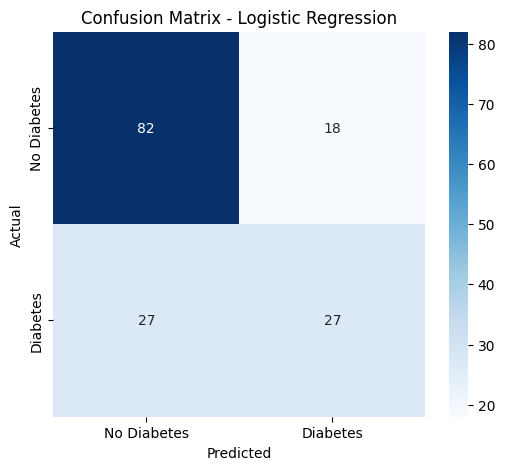


Model Evaluation:
-----------------
Accuracy : 70.78 %
Precision: 60.0 %
Recall   : 50.0 %
F1 Score : 54.55 %


In [8]:
# ----------------------------------
# Step 8: Model Evaluation
# ----------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

# Calculate metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display metrics
print("\nModel Evaluation:")
print("-----------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

In [9]:
# ----------------------------------
# Step 9: Train Multiple ML Models
# ----------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ----------------------------------
# Create models
# ----------------------------------

logistic_model = LogisticRegression()

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

random_forest_model = RandomForestClassifier(
    random_state=42
)

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

svm_model = SVC(
    probability=True,
    random_state=42
)

# ----------------------------------
# Train models
# ----------------------------------

logistic_model.fit(X_train_scaled, y_train)

decision_tree_model.fit(X_train_scaled, y_train)

random_forest_model.fit(X_train_scaled, y_train)

knn_model.fit(X_train_scaled, y_train)

svm_model.fit(X_train_scaled, y_train)

# ----------------------------------
# Predictions
# ----------------------------------

logistic_pred = logistic_model.predict(X_test_scaled)

decision_tree_pred = decision_tree_model.predict(X_test_scaled)

random_forest_pred = random_forest_model.predict(X_test_scaled)

knn_pred = knn_model.predict(X_test_scaled)

svm_pred = svm_model.predict(X_test_scaled)

# ----------------------------------
# Store predictions
# ----------------------------------

models_predictions = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": decision_tree_pred,
    "Random Forest": random_forest_pred,
    "KNN": knn_pred,
    "SVM": svm_pred
}

# ----------------------------------
# Evaluate models
# ----------------------------------

results = []

for name, predictions in models_predictions.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

# ----------------------------------
# Create comparison table
# ----------------------------------

results_df = pd.DataFrame(results)

# Sort by F1 Score
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

# Convert to percentage for display
results_display = results_df.copy()

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_display[metrics] = results_display[metrics] * 100

print("\nModel Comparison:")
print(results_display.round(2).to_string(index=False))


Model Comparison:
              Model  Accuracy  Precision  Recall  F1 Score
      Random Forest     77.92      71.74   61.11     66.00
                KNN     75.32      66.00   61.11     63.46
                SVM     74.03      65.22   55.56     60.00
Logistic Regression     70.78      60.00   50.00     54.55
      Decision Tree     68.18      55.32   48.15     51.49


Starting Hyperparameter Tuning...
Please wait...

Hyperparameter Tuning Completed!

BEST PARAMETERS
{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}

BEST CROSS-VALIDATION F1 SCORE
F1 Score: 64.74%

TUNED RANDOM FOREST RESULTS
Accuracy  : 75.32%
Precision : 66.67%
Recall    : 59.26%
F1 Score  : 62.75%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.79      0.84      0.82       100
           1       0.67      0.59      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154


CONFUSION MATRIX
[[84 16]
 [22 32]]


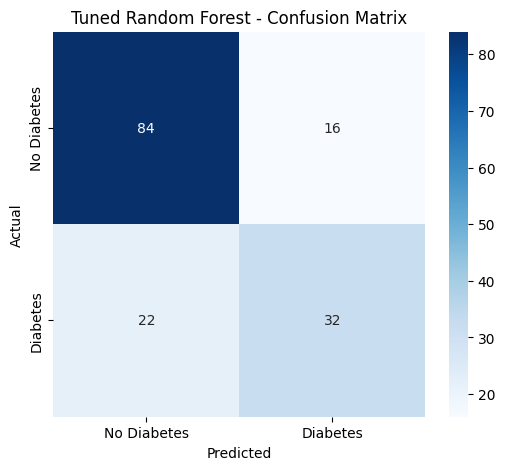

In [10]:
# ============================================================
# STEP 10: RANDOM FOREST HYPERPARAMETER TUNING
# Diabetes Prediction using Machine Learning
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 2. DEFINE HYPERPARAMETERS TO TEST
# ------------------------------------------------------------

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}


# ------------------------------------------------------------
# 3. CREATE GRID SEARCH
# ------------------------------------------------------------

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)


# ------------------------------------------------------------
# 4. TRAIN GRID SEARCH
# ------------------------------------------------------------

print("Starting Hyperparameter Tuning...")
print("Please wait...\n")

grid_search.fit(X_train_scaled, y_train)

print("Hyperparameter Tuning Completed!\n")


# ------------------------------------------------------------
# 5. DISPLAY BEST PARAMETERS
# ------------------------------------------------------------

print("==============================================")
print("BEST PARAMETERS")
print("==============================================")

print(grid_search.best_params_)


# ------------------------------------------------------------
# 6. DISPLAY BEST CROSS-VALIDATION F1 SCORE
# ------------------------------------------------------------

print("\n==============================================")
print("BEST CROSS-VALIDATION F1 SCORE")
print("==============================================")

print(
    "F1 Score: {:.2f}%".format(
        grid_search.best_score_ * 100
    )
)


# ------------------------------------------------------------
# 7. GET THE BEST RANDOM FOREST MODEL
# ------------------------------------------------------------

tuned_rf_model = grid_search.best_estimator_


# ------------------------------------------------------------
# 8. MAKE PREDICTIONS ON TEST DATA
# ------------------------------------------------------------

tuned_rf_pred = tuned_rf_model.predict(X_test_scaled)


# ------------------------------------------------------------
# 9. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

tuned_accuracy = accuracy_score(
    y_test,
    tuned_rf_pred
)

tuned_precision = precision_score(
    y_test,
    tuned_rf_pred
)

tuned_recall = recall_score(
    y_test,
    tuned_rf_pred
)

tuned_f1 = f1_score(
    y_test,
    tuned_rf_pred
)


# ------------------------------------------------------------
# 10. DISPLAY PERFORMANCE
# ------------------------------------------------------------

print("\n==============================================")
print("TUNED RANDOM FOREST RESULTS")
print("==============================================")

print(
    "Accuracy  : {:.2f}%".format(
        tuned_accuracy * 100
    )
)

print(
    "Precision : {:.2f}%".format(
        tuned_precision * 100
    )
)

print(
    "Recall    : {:.2f}%".format(
        tuned_recall * 100
    )
)

print(
    "F1 Score  : {:.2f}%".format(
        tuned_f1 * 100
    )
)


# ------------------------------------------------------------
# 11. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n==============================================")
print("CLASSIFICATION REPORT")
print("==============================================")

print(
    classification_report(
        y_test,
        tuned_rf_pred
    )
)


# ------------------------------------------------------------
# 12. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    tuned_rf_pred
)

print("\n==============================================")
print("CONFUSION MATRIX")
print("==============================================")

print(cm)


# ------------------------------------------------------------
# 13. DISPLAY CONFUSION MATRIX AS HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Diabetes",
        "Diabetes"
    ],
    yticklabels=[
        "No Diabetes",
        "Diabetes"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Tuned Random Forest - Confusion Matrix"
)

plt.show()

In [11]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Original Random Forest predictions
original_pred = random_forest_model.predict(X_test_scaled)

# Tuned Random Forest predictions
tuned_pred = tuned_rf_model.predict(X_test_scaled)

# Compare models
comparison = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "Accuracy": accuracy_score(y_test, original_pred) * 100,
        "Precision": precision_score(y_test, original_pred) * 100,
        "Recall": recall_score(y_test, original_pred) * 100,
        "F1 Score": f1_score(y_test, original_pred) * 100
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": accuracy_score(y_test, tuned_pred) * 100,
        "Precision": precision_score(y_test, tuned_pred) * 100,
        "Recall": recall_score(y_test, tuned_pred) * 100,
        "F1 Score": f1_score(y_test, tuned_pred) * 100
    }
])

print(comparison.round(2).to_string(index=False))

                 Model  Accuracy  Precision  Recall  F1 Score
Original Random Forest     77.92      71.74   61.11     66.00
   Tuned Random Forest     75.32      66.67   59.26     62.75


In [12]:
import joblib

# Save the selected model and scaler together
model_data = {
    "model": random_forest_model,
    "scaler": scaler,
    "feature_names": list(X.columns)
}

joblib.dump(model_data, "/kaggle/working/diabetes_model.pkl")

print("Model saved successfully!")
print("File: /kaggle/working/diabetes_model.pkl")

Model saved successfully!
File: /kaggle/working/diabetes_model.pkl


In [13]:
import os

path = "/kaggle/working/diabetes_model.pkl"

print("File exists:", os.path.exists(path))

File exists: True


In [14]:
import os
import joblib

model_data = {
    "model": random_forest_model,
    "scaler": scaler,
    "feature_names": list(X.columns)
}

save_path = "/kaggle/working/diabetes_model.pkl"

joblib.dump(model_data, save_path)

print("Model saved:", os.path.exists(save_path))
print("File location:", save_path)

Model saved: True
File location: /kaggle/working/diabetes_model.pkl


In [15]:
import os

print(os.listdir("/kaggle/working"))

['diabetes_model.pkl', '__notebook__.ipynb']


In [16]:
from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/diabetes_model.pkl"
))

/kaggle/working/diabetes_model.pkl

In [17]:
from IPython.display import display, FileLink
import os

model_path = "/kaggle/working/diabetes_model.pkl"

if os.path.exists(model_path):
    print("Model file found!")
    display(FileLink(model_path, result_html_prefix="Download your model: "))
else:
    print("Model file not found. Save the model again.")

Model file found!


/kaggle/working/diabetes_model.pkl

In [18]:
import shutil
import os

shutil.make_archive(
    "/kaggle/working/diabetes_model_download",
    "zip",
    "/kaggle/working",
    "diabetes_model.pkl"
)

print("ZIP file created successfully!")
print(os.path.exists("/kaggle/working/diabetes_model_download.zip"))

ZIP file created successfully!
True
